# Residence Time Distribution of the Packed-Bed Reactor

In the packed-bed reactor, not every fluid element spends the same amount of time in contact with the catalyst. Some find fast paths between the beads while others linger in slower regions. A tracer pulse injected at the inlet and measured at the outlet records this spread as a concentration curve, C(t). This notebook turns each run's curve into a residence time distribution, E(t), and summarizes it with two numbers: the mean residence time and the variance around it.

The data file, `RTD_data.csv`, must be in the same folder as this notebook. It holds one row per time point, with columns for the run number, the time in seconds, the measured tracer concentration, and the flow rate for that run in mL/min.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import trapezoid

## Loading and cleaning the data

The cell below reads the file and strips any stray spaces from the column headers, which spreadsheet exports often add. Near the baseline the instrument reading fluctuates around zero, so some recorded concentrations come out slightly negative. A negative concentration has no physical meaning, so these values are set to zero before any integration. The first few rows are shown so you can confirm the file loaded correctly.

In [4]:
file_path = "RTD_data.csv"
df = pd.read_csv(file_path)

# Remove stray spaces from the column headers
df.columns = [col.strip() for col in df.columns]

# Set negative concentrations to zero
df["Concentration (C)"] = df["Concentration (C)"].clip(lower=0)

df.head()

,Time (s),Concentration (C),Flow Rate (mL/min),Run
0,0,0.0,20,1
1,1,0.0,20,1
2,2,0.0,20,1
3,3,0.0,20,1
4,4,0.0,20,1


## From concentration to E(t)

The raw curve depends on how much tracer was injected, so it cannot be compared directly between runs. Dividing by the area under the curve removes that dependence and gives the residence time distribution,

$$E(t) = \frac{C(t)}{\int_0^\infty C(t)\,dt}$$

which has an area of exactly one. The quantity E(t) dt is the fraction of fluid that leaves the reactor between t and t + dt. The mean residence time is the first moment of this distribution,

$$\tau = \int_0^\infty t\,E(t)\,dt$$

and the variance, σ², measures how widely the residence times spread around that mean,

$$\sigma^2 = \int_0^\infty (t - \tau)^2\,E(t)\,dt$$

Because the data are discrete points rather than a continuous curve, each integral is evaluated with the trapezoid rule, which connects neighboring points with straight lines and adds up the areas underneath. The function below carries out all three calculations for a single run.

In [6]:
def rtd_moments(t, C):
    # Normalize the concentration curve to get E(t)
    E = C / trapezoid(C, t)

    # Mean residence time
    tau = trapezoid(t * E, t)

    # Variance
    sigma_squared = trapezoid((t - tau) ** 2 * E, t)

    return E, tau, sigma_squared

## Analyzing each run

The loop below pulls out the data for each run and computes E(t) and its moments. Each run's curve is kept so the runs can be plotted together and then one at a time.

In [8]:
results = []
curves = []

for run_id in df["Run"].unique():
    run_data = df[df["Run"] == run_id]

    t = run_data["Time (s)"].values
    C = run_data["Concentration (C)"].values
    Q_mL_min = run_data["Flow Rate (mL/min)"].values[0]

    E, tau, sigma_squared = rtd_moments(t, C)

    results.append({
        "Run": run_id,
        "Flow Rate (mL/min)": Q_mL_min,
        "Mean Residence Time (s)": round(tau, 2),
        "Variance (s²)": round(sigma_squared, 2),
    })
    curves.append({"run_id": run_id, "Q_mL_min": Q_mL_min, "t": t, "E": E, "tau": tau})

## Comparing the runs

Plotting every run on the same axes lets you compare the distributions across flow rates. Each run is drawn in its own color, and the legend gives its flow rate. The figure is saved as `RTD_all_runs.png` in the `rtd_plots` folder, which you can download for your report.

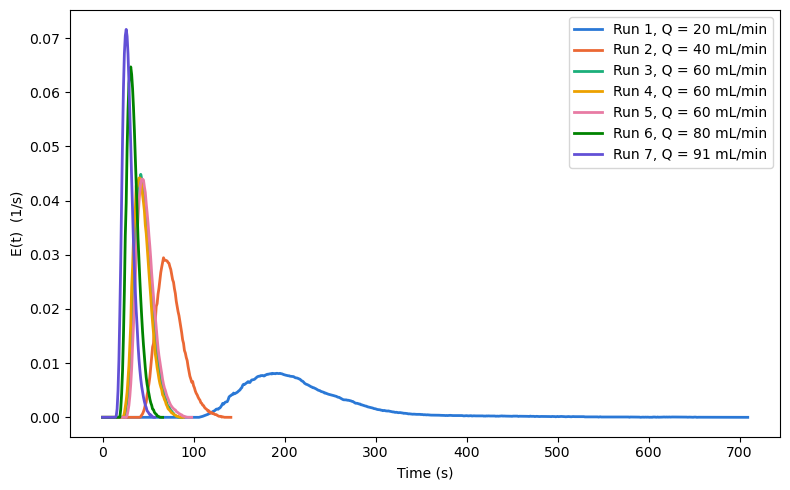

In [10]:
plot_dir = "rtd_plots"
os.makedirs(plot_dir, exist_ok=True)

# One distinct color per run, chosen to stay distinguishable for colorblind readers
colors = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
          "#e87ba4", "#008300", "#6250d6", "#e34948"]

plt.figure(figsize=(8, 5))
for i, c in enumerate(curves):
    plt.plot(c["t"], c["E"], color=colors[i % len(colors)], linewidth=2,
             label=f"Run {c['run_id']}, Q = {c['Q_mL_min']} mL/min")

plt.xlabel("Time (s)")
plt.ylabel("E(t)  (1/s)")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(plot_dir, "RTD_all_runs.png"))
plt.show()

## Individual runs

Each run is also plotted on its own, with the mean residence time marked as a dashed line. These plots are saved as PNGs in the same `rtd_plots` folder.

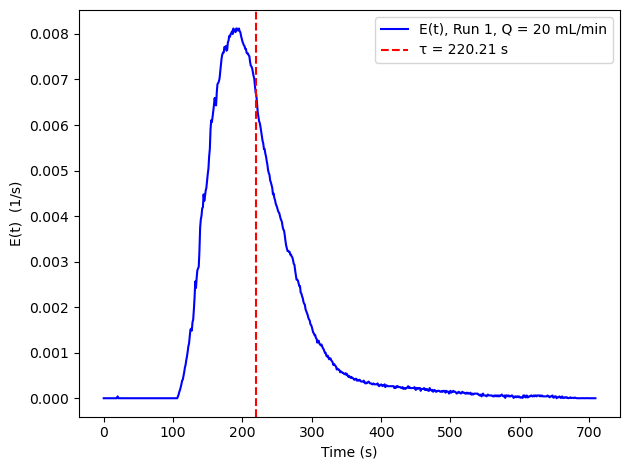

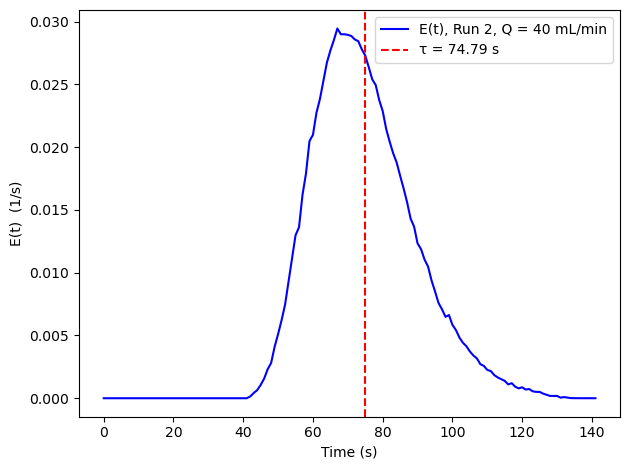

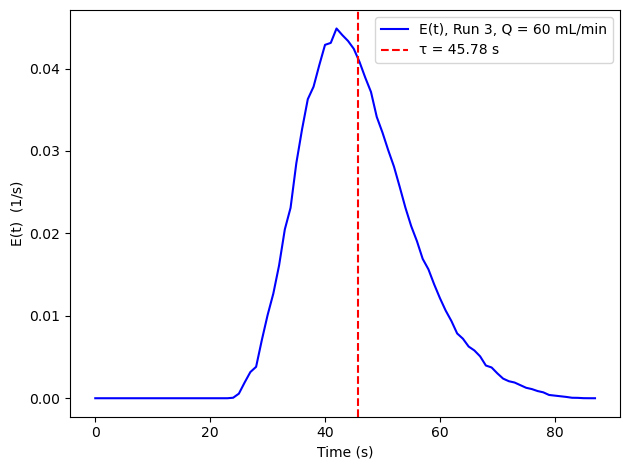

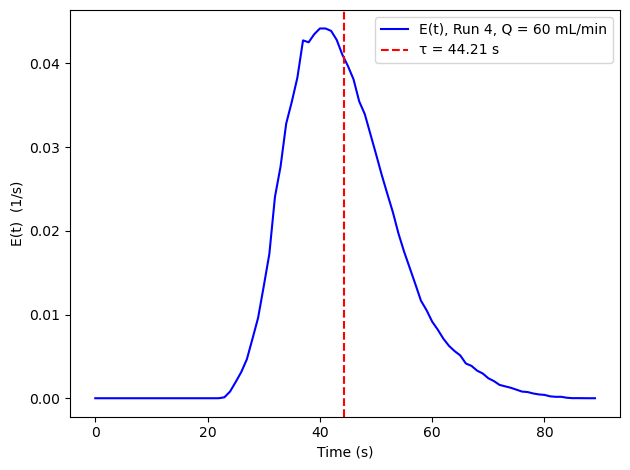

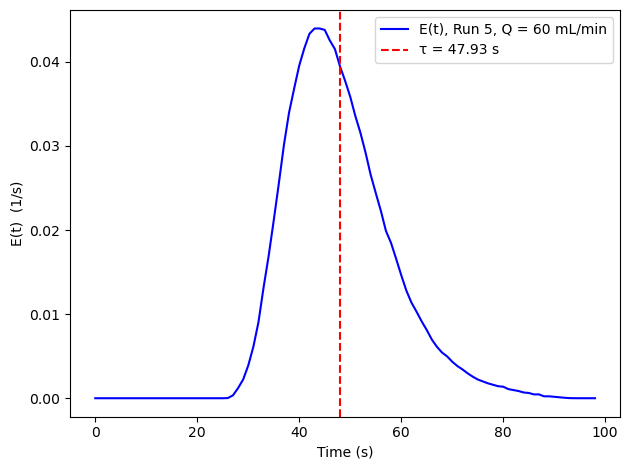

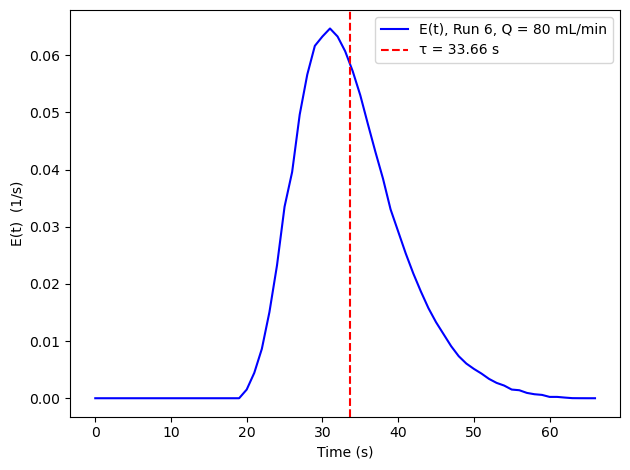

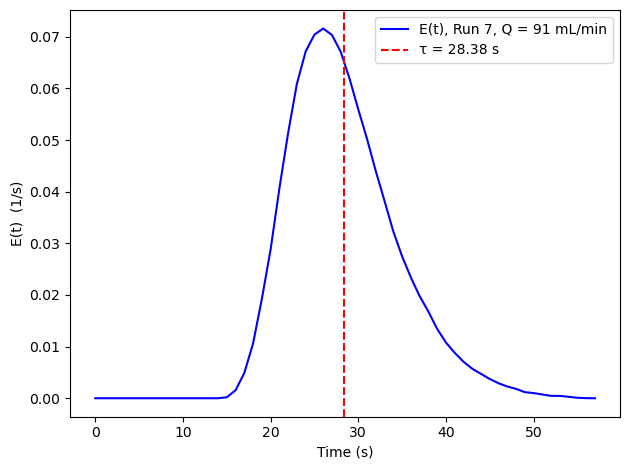

In [12]:
for c in curves:
    run_id, Q_mL_min, t, E, tau = c["run_id"], c["Q_mL_min"], c["t"], c["E"], c["tau"]

    # Plot E(t) with the mean residence time marked
    plt.figure()
    plt.plot(t, E, label=f"E(t), Run {run_id}, Q = {Q_mL_min} mL/min", color="blue")
    plt.axvline(tau, color="red", linestyle="--", label=f"τ = {tau:.2f} s")
    plt.xlabel("Time (s)")
    plt.ylabel("E(t)  (1/s)")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(plot_dir, f"RTD_Run_{run_id}.png"))
    plt.show()

## Summary of results

The table collects the flow rate, mean residence time, and variance for every run. The same values are saved to `RTD_results_clean.csv` so you can bring them into your spreadsheet or report.

In [14]:
results_df = pd.DataFrame(results)
results_df.to_csv("RTD_results_clean.csv", index=False)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)
results_df

,Run,Flow Rate (mL/min),Mean Residence Time (s),Variance (s²)
0,1,20,220.21,5077.88
1,2,40,74.79,205.68
2,3,60,45.78,89.39
3,4,60,44.21,88.73
4,5,60,47.93,98.48
5,6,80,33.66,44.48
6,7,91,28.38,36.56
